Import Necesssary Libraries & Load iris
==

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.tree import plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
sns.set_style('ticks')
sns.set_style('whitegrid')

 1. Load tips.csv
 2. Feature is total_bill, your Target is tip.
 

In [4]:
df = pd.read_csv("tips.csv")

In [5]:
df.head(10)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


Features, target, and the split
==========

In [6]:
from sklearn.model_selection import train_test_split
X = df[["total_bill"]]
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [7]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (170, 1)
X_test: (74, 1)
y_train: (170,)
y_test: (74,)


In [8]:
len(X_train)

170

Why hold out 30%?
=
You do not want your model trained on 100% of the data, because the model would memorize your query answers through retrieval of data. The model wouldn/t be trained and tested properly with training on all the data. Witholding 30% allows for a subjective tests that properly scores the models ability to learn via machine learning algorithms.

Fit, predict, score
=========

In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.4291782688312412


Reading a fitted line
model.coef_ holds the slope(s) 
=====
"Each extra dollar adds $ 0.11 d0llars (11 cents) of tip.”

In [10]:
print(model.coef_, model.intercept_)

[0.10889371] 0.8769576391532707


<Axes: xlabel='total_bill', ylabel='tip'>

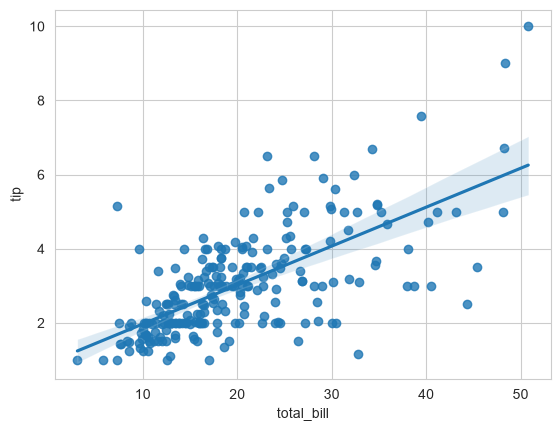

In [11]:
sns.regplot(x="total_bill", y="tip", data=df)

Plot Analysis
===
As expected, the plot reveals an upward cloud with a line through it.

Split iris
===

In [12]:
iris = load_iris(as_frame=True)

In [13]:
df1 = iris.frame

In [14]:
display(df1.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0


In [15]:
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (105, 4)
Testing data: (45, 4)


Fit and score kNN
===

In [16]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
test_accuracy = knn.score(X_test, y_test)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 1.0


Fit, score, and read a shallow tree
=========

Test Accuracy: 1.0


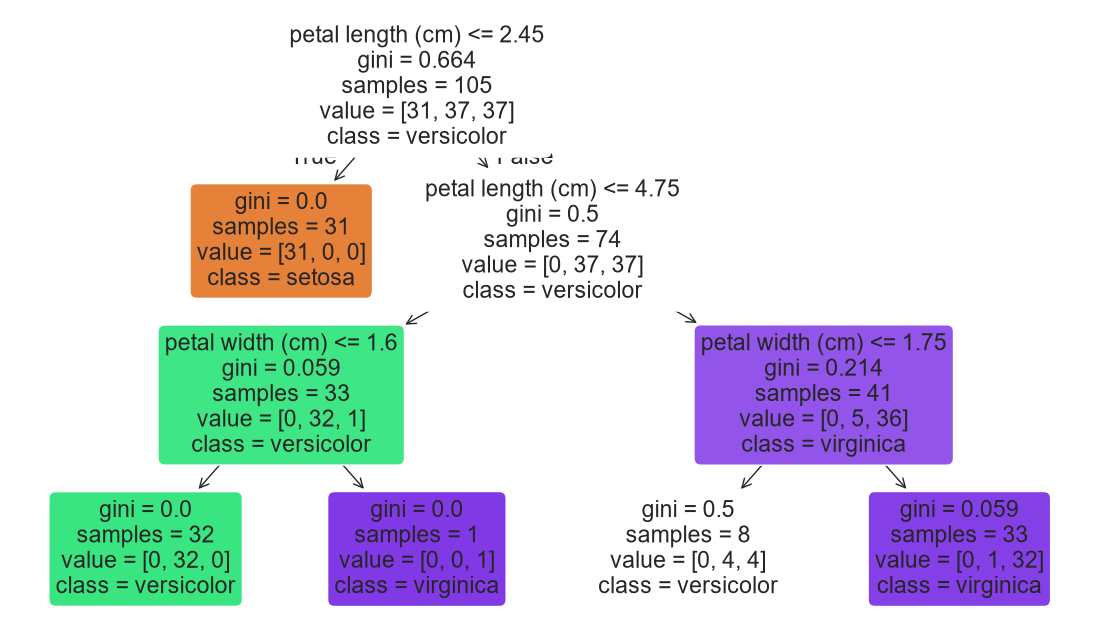

In [20]:
tree_lrnd1 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_lrnd1.fit(X_train, y_train)

print("Test Accuracy:", tree_lrnd1.score(X_test, y_test))

plt.figure(figsize=(14, 8))
plot_tree(
    tree_lrnd1,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.show()

Translate the root split into a plain sentence.
==

The threshold of 2.45 cn or less splits the population on the left side at Setosa then traverses the tree on the right side to make other targert decisions.

Refit the tree with NO max_depth.
=

In [22]:
tree_lrnd2 = DecisionTreeClassifier(max_depth=1, random_state=42)
tree_lrnd2.fit(X_train, y_train)

print("Test Accuracy for NO max_depth on test data:", tree_lrnd2.score(X_test, y_test))
print("Test Accuracy for max_depth = 3 on test data:", tree_lrnd1.score(X_test, y_test))

print("Test Accuracy for NO max_depth on training data:", tree_lrnd2.score(X_train, y_train))
print("Test Accuracy for max_depth = 3 on training data:", tree_lrnd1.score(X_train, y_train))

Test Accuracy for NO max_depth on test data: 0.7111111111111111
Test Accuracy for max_depth = 3 on test data: 1.0
Test Accuracy for NO max_depth on training data: 0.6476190476190476
Test Accuracy for max_depth = 3 on training data: 0.9523809523809523


The overfitting probe
==
There is possible overfitting as, train score ≈ 1.0, test score lower. However, since train score ~ test score, then the model performs generally well. The unlimited tree hits 1.00 on test but does not beat the shallow tree on train.

Predict one new flower
========
versicolor


sepal length (cm)	sepal width (cm)	petal length (cm)	petal width (cm)	target
0	  5.0	        3.6	                1.4	                1.6                   0

The model report 
==========


Score the SAME model twice: on training data and on test data. There is NOT a large gap which means the model learned and not memorized. If the model were about people, it would mot detect ad-mixture as people are not clearly racially distinct. It might fail for a new species not defined by the established limits
=

In [23]:
print(tree_lrnd1.score(X_train, y_train))
print(tree_lrnd1.score(X_test, y_test))

0.9523809523809523
1.0


URL for This Assignmemnt's Repo
================================================================================

https://github.com/chillyvee70/cs82a-portfolio/tree/main/module7